# 2D Cantilever Problem with PINNs
## (Linear Elastic Regime)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import os, json, glob
import pandas as pd

# Set default tensor type and device
torch.set_default_dtype(torch.float64)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Check if MPS is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

/home/ashkreli/.local/lib/python3.10/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
# Material and geometric parameters
E = 1e3           # Young's modulus
nu = 0.25         # Poisson's ratio
P = 2.0           # Applied load
L = 8.0           # Length of the beam
W = 2.0           # Width of the beam
b = 1.0           # Depth of the beam
I = b * W**3 / 12.0   # Moment of inertia
lambda_ = E * nu / ((1 + nu)*(1 - 2*nu))  # Lamé's first parameter
#lambda_ = E * nu / (1 - nu**2)   # plane stress, matches the Timoshenko solution
mu = E / (2*(1 + nu))  # Lamé's second parameter (shear modulus)

# collocation point parameters
Nx, Ny = 80, 40  # Original grid size

# NN architecture
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        hdim = 20
        self.layers = nn.Sequential(
            nn.Linear(2, hdim),
            nn.Tanh(),
            nn.Linear(hdim, hdim),
            nn.Tanh(),
            nn.Linear(hdim, hdim),
            nn.Tanh(),
            nn.Linear(hdim, hdim),
            nn.Tanh(),
            nn.Linear(hdim, 2)
        )

    def forward(self, x, y):
        inputs = torch.cat((x, y), dim=1)
        # inputs = torch.tanh(inputs)
        outputs = self.layers(inputs)
        return outputs[:, 0:1], outputs[:, 1:2]
        
# Functions for later computations
def linear_distance(x, L):
    """Current simple linear distance function"""
    return x/L

def polynomial_distance(x, L, n=3):
    """Polynomial distance function
    n: polynomial degree (odd number)"""
    return (x/L)**n * (1 - (x/L))**(n-1) + x/L

# The correct strong form enforcement
def net_u(x, y):
    u_NN, _ = model(x, y)
    # Analytical solution at x=0
    g_u = (P * y) / (6 * E * I) * ((2 + nu) * (y**2 - W**2/4))
    return g_u + polynomial_distance(x, L) * u_NN

def net_v(x, y):
    _, v_NN = model(x, y)
    # Analytical solution at x=0
    g_v = -(P) / (6 * E * I) * (3 * nu * y**2 * L)
    return g_v + polynomial_distance(x, L) * v_NN

def strain(x, y):
    u = net_u(x, y)
    v = net_v(x, y)

    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                             create_graph=True)[0]
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u),
                             create_graph=True)[0]
    v_x = torch.autograd.grad(v, x, grad_outputs=torch.ones_like(v),
                             create_graph=True)[0]
    v_y = torch.autograd.grad(v, y, grad_outputs=torch.ones_like(v),
                             create_graph=True)[0]

    epsilon_xx = u_x
    epsilon_yy = v_y
    epsilon_xy = 0.5 * (u_y + v_x)

    return epsilon_xx, epsilon_yy, epsilon_xy

def stress(x, y):
    epsilon_xx, epsilon_yy, epsilon_xy = strain(x, y)

    sigma_xx = lambda_ * (epsilon_xx + epsilon_yy) + 2 * mu * epsilon_xx
    sigma_yy = lambda_ * (epsilon_xx + epsilon_yy) + 2 * mu * epsilon_yy
    sigma_xy = 2 * mu * epsilon_xy

    return sigma_xx, sigma_yy, sigma_xy

def traction_x(y):
    return torch.zeros_like(y)

def traction_y(y):
    return P * (y**2 - y * W) / (2 * I)

def potential_energy(colloc_pts):
    X_star, X_boundary, x_collocation, y_collocation, \
    x_boundary_tensor, y_boundary_tensor = colloc_pts.collocation_points()

    # Get strains and stresses at collocation points
    epsilon_xx, epsilon_yy, epsilon_xy = strain(x_collocation, y_collocation)

    # Compute strain energy density
    # First term: λ(εxx + εyy)^2
    psi_1 = 0.5 * lambda_ * (epsilon_xx + epsilon_yy)**2

    # Second term: μ(εxx^2 + εyy^2 + 2εxy^2)
    psi_2 = mu * (epsilon_xx**2 + epsilon_yy**2 + 2 * epsilon_xy**2)

    # Total strain energy density
    strain_energy_density = psi_1 + psi_2

    # Numerical integration over domain
    dx = L / (Nx - 2)  # Adjusted for excluding x=0
    dy = W / (Ny - 2)  # Adjusted for excluding boundaries
    area_element = dx * dy

    # Internal energy = ∫∫ Ψ dxdy
    #internal_energy = (strain_energy_density * area_element).sum()
    internal_energy = (strain_energy_density * colloc_pts.weights).sum()

    # External work from traction on right boundary
    # Get displacements on right boundary
    u_right = net_u(x_boundary_tensor[:Ny], y_boundary_tensor[:Ny])
    v_right = net_v(x_boundary_tensor[:Ny], y_boundary_tensor[:Ny])

    # Traction components on right boundary
    t_x_right = torch.zeros_like(y_boundary_tensor[:Ny])
    t_y_right = P * (y_boundary_tensor[:Ny]**2 - y_boundary_tensor[:Ny] * W) / (2 * I)

    # External work = -∫ t·u dΓ
    external_work = ((t_x_right * u_right + t_y_right * v_right) * (W/(Ny-1))).sum()

    # Total potential energy = Internal + External
    total_energy = internal_energy + external_work

    return total_energy

In [3]:
# Initialize model and move to device
model = Net().to(device)

# Initialize weights properly
torch.manual_seed(42)
for m in model.layers:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

In [4]:
# set up collocation points

# class for the collocation point params
class CollocPts:
    def __init__(self, X_star, X_boundary,
                 x_collocation, y_collocation,
                 x_boundary_tensor, y_boundary_tensor,
                 x_edges=None, y_edges=None, max_pts=None):
        self.X_star = X_star
        self.X_boundary = X_boundary
        self.x_collocation = x_collocation
        self.y_collocation = y_collocation
        self.x_boundary_tensor = x_boundary_tensor
        self.y_boundary_tensor = y_boundary_tensor

        # Point budget: interior points of the full grid (start_frac = 1)
        if max_pts is None:
            max_pts = (Nx - 1) * (Ny - 2)
        self.max_pts = max_pts

        # Bin edges halfway between base grid points, outer edges on the domain boundary
        if x_edges is None:
            x_unique = np.unique(X_star[:, 0])
            x_edges = np.concatenate(([0.0], 0.5 * (x_unique[:-1] + x_unique[1:]), [L]))
        if y_edges is None:
            y_unique = np.unique(X_star[:, 1])
            y_edges = np.concatenate(([0.0], 0.5 * (y_unique[:-1] + y_unique[1:]), [W]))
        self.x_edges = x_edges
        self.y_edges = y_edges
        self.weights = self.quadrature_weights()

    def quadrature_weights(self):
        # Each point gets (area of its bin) / (number of points in that bin)
        counts, _, _ = np.histogram2d(self.X_star[:, 0], self.X_star[:, 1],
                                      bins=[self.x_edges, self.y_edges])
        n_bins_x, n_bins_y = len(self.x_edges) - 1, len(self.y_edges) - 1
        i_x = np.clip(np.digitize(self.X_star[:, 0], self.x_edges) - 1, 0, n_bins_x - 1)
        i_y = np.clip(np.digitize(self.X_star[:, 1], self.y_edges) - 1, 0, n_bins_y - 1)
        bin_area = np.outer(np.diff(self.x_edges), np.diff(self.y_edges))
        weights = bin_area[i_x, i_y] / counts[i_x, i_y]

        return torch.tensor(weights[:, None], dtype=self.x_collocation.dtype,
                            device=self.x_collocation.device)

    def collocation_points(self):
        return self.X_star, self.X_boundary, \
                self.x_collocation, self.y_collocation, \
                self.x_boundary_tensor, self.y_boundary_tensor

    def place_pts(self, X_new):
        # Append new interior points and rebuild tensors and weights
        self.X_star = np.vstack((self.X_star, X_new))
        self.x_collocation = torch.tensor(self.X_star[:, 0:1], dtype=self.x_collocation.dtype,
                                        requires_grad=True, device=self.x_collocation.device)
        self.y_collocation = torch.tensor(self.X_star[:, 1:2], dtype=self.y_collocation.dtype,
                                        requires_grad=True, device=self.y_collocation.device)
        self.weights = self.quadrature_weights()


    def add_pts(self, add_frac=0.1, n_candidates=10000, mode="topk",
                    k=1.0, c=1.0, seed=None, batch=5000, place=True,
                    skip_covered=False):
        """
        Add interior collocation points, within the total budget (max_pts).

        add_frac     : fraction of the total budget to add in this call,
                    capped so len(X_star) never exceeds max_pts
        mode="topk"  : take the candidates with highest strain energy density
        mode="sample": sample with prob ∝ psi^k / mean(psi^k) + c
                    (k sharpens focus, c keeps some uniform coverage)
        mode="grid"  : add a uniform cell-centered grid, staggered between
                    existing points, same aspect ratio as the original grid
        skip_covered : (grid only) drop new grid points that already have an
                    existing point within half a grid spacing
        n_candidates : random points evaluated for "topk"/"sample"
                    (keep this well above add_frac * max_pts)
        place=True   : append the new points to this object
        place=False  : only return them
        """
        # Budget check
        n_remaining = self.max_pts - len(self.X_star)
        n_new = min(int(add_frac * self.max_pts), n_remaining)
        if n_new <= 0:
            return np.empty((0, 2))      # budget used up, nothing added

        # ---------- Uniform grid refinement ----------
        if mode == "grid":
            # Points per axis, keeping the original (Nx-1):(Ny-2) proportions.
            # int() rounds down so the grid never exceeds n_new.
            scale = np.sqrt(n_new / ((Nx - 1) * (Ny - 2)))
            n_x = int(scale * (Nx - 1))
            n_y = int(scale * (Ny - 2))
            if n_x == 0 or n_y == 0:
                return np.empty((0, 2))    # slice too small to form a grid

            # Cell centers: excludes x=0, y=0, y=W and sits between existing points
            x = (np.arange(n_x) + 0.5) * L / n_x
            y = (np.arange(n_y) + 0.5) * W / n_y
            X, Y = np.meshgrid(x, y)
            X_new = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

            # Optionally drop grid points already covered by existing points
            if skip_covered:
                from scipy.spatial import cKDTree
                dist, _ = cKDTree(self.X_star).query(X_new)
                spacing = min(L / n_x, W / n_y)
                X_new = X_new[dist > 0.5 * spacing]

            if place:
                self.place_pts(X_new)
            return X_new

        # ---------- Energy-based refinement ----------
        rng = np.random.default_rng(seed)
        dtype = self.x_collocation.dtype
        dev = self.x_collocation.device

        # Random interior candidates (x > 0, 0 < y < W), like the original scheme
        x_candidate = rng.uniform(0, L, n_candidates)
        y_candidate = rng.uniform(0, W, n_candidates)
        interior = (x_candidate > 0) & (y_candidate > 0) & (y_candidate < W)
        X_candidate = np.stack([x_candidate[interior], y_candidate[interior]], axis=1)

        # Strain energy density at candidates, in batches
        strain_energy_density = []
        for i in range(0, len(X_candidate), batch):
            X_batch = X_candidate[i:i + batch]
            x_batch = torch.tensor(X_batch[:, 0:1], dtype=dtype, requires_grad=True, device=dev)
            y_batch = torch.tensor(X_batch[:, 1:2], dtype=dtype, requires_grad=True, device=dev)

            epsilon_xx, epsilon_yy, epsilon_xy = strain(x_batch, y_batch)
            psi_1 = 0.5 * lambda_ * (epsilon_xx + epsilon_yy)**2
            psi_2 = mu * (epsilon_xx**2 + epsilon_yy**2 + 2 * epsilon_xy**2)

            strain_energy_density.append((psi_1 + psi_2).detach().abs().reshape(-1).cpu().numpy())
        strain_energy_density = np.concatenate(strain_energy_density)

        # Select struggling points
        n_new = min(n_new, len(X_candidate))
        if mode == "topk":
            idx = np.argpartition(strain_energy_density, -n_new)[-n_new:]
        elif mode == "sample":
            psi_k = strain_energy_density ** k
            prob = psi_k / psi_k.mean() + c
            idx = rng.choice(len(X_candidate), n_new, replace=False, p=prob / prob.sum())
        else:
            raise ValueError(f"Unknown mode '{mode}' (use 'topk', 'sample', or 'grid')")
        X_new = X_candidate[idx]

        if place:
            self.place_pts(X_new)
        return X_new

    def plot_collocation_points(self, title='Collocation Points', save_path=None):
        # Plot collocation points
        plt.figure(figsize=(8, 4))

        # Interior points (blue)
        plt.scatter(self.X_star[:, 0], self.X_star[:, 1], c='blue', s=2, alpha=0.6, label='Interior')

        # Boundary points (red)
        plt.scatter(self.X_boundary[:, 0], self.X_boundary[:, 1], c='red', s=4, label='Boundary')

        plt.title(f'{title} ({len(self.X_star)} interior points)')
        plt.xlabel('x')
        plt.ylabel('y')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.3)

        # Save the plot if a path is given
        if save_path is not None:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()

def original_collocation_point_scheme(start_frac=1.0):
    # Generate interior collocation points (excluding x=0)
    # Interior points per axis, scaled so the total is ~start_frac of the full-grid budget
    n_x = max(1, round(np.sqrt(start_frac) * (Nx - 1)))
    n_y = max(1, round(np.sqrt(start_frac) * (Ny - 2)))
    x = np.linspace(0, L, n_x + 1)[1:]     # Exclude x=0 point
    y = np.linspace(0, W, n_y + 2)[1:-1]   # Exclude top and bottom boundaries
    X, Y = np.meshgrid(x, y)
    X_star = np.hstack((X.flatten()[:, None], Y.flatten()[:, None]))

    # Generate boundary points
    # Right boundary (x = L)
    y_right = np.linspace(0, W, Ny)
    x_right = L * np.ones_like(y_right)
    X_right = np.hstack((x_right[:, None], y_right[:, None]))

    # Top boundary (y = W/2)
    x_top = np.linspace(0, L, Nx)#[1:]  # Exclude x=0
    y_top = (W) * np.ones_like(x_top)
    X_top = np.hstack((x_top[:, None], y_top[:, None]))

    # Bottom boundary (y = -W/2)
    x_bottom = np.linspace(0, L, Nx)#[1:]  # Exclude x=0
    y_bottom =  0 * np.ones_like(x_bottom) #(-W/2)
    X_bottom = np.hstack((x_bottom[:, None], y_bottom[:, None]))

    # Combine all boundary points
    X_boundary = np.vstack((X_right, X_top, X_bottom))

    # Convert to torch tensors
    x_collocation = torch.tensor(X_star[:, 0:1], requires_grad=True, device=device)
    y_collocation = torch.tensor(X_star[:, 1:2], requires_grad=True, device=device)

    x_boundary_tensor = torch.tensor(X_boundary[:, 0:1], requires_grad=True, device=device)
    y_boundary_tensor = torch.tensor(X_boundary[:, 1:2], requires_grad=True, device=device)

    colloc_pts = CollocPts(X_star, X_boundary, x_collocation, y_collocation, x_boundary_tensor, y_boundary_tensor)

    return colloc_pts

In [5]:
def save_run(run_name, metadata, colloc_history=None, folder='runs'):
    """Evaluate on the common test grid, save model + results + collocation points, print errors."""
    os.makedirs(folder, exist_ok=True)

    def u_exact(x, y):
        term1 = (P * (y-W/2)) / (6 * E * I)
        term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4)
        return -term1 * term2

    def v_exact(x, y):
        term1 = -(P) / (6 * E * I)
        term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
        return -term1 * term2

    # Common testing grid
    x_test = np.linspace(0, L, 2*Nx)
    y_test = np.linspace(0, W, 2*Ny)
    X_test, Y_test = np.meshgrid(x_test, y_test)
    X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

    x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
    y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

    # Predict displacements
    u_pred = net_u(x_test_tensor, y_test_tensor).cpu().detach().numpy()
    v_pred = net_v(x_test_tensor, y_test_tensor).cpu().detach().numpy()

    u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
    v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])

    # Relative L2 errors
    error_u = np.linalg.norm(u_exact_val - u_pred, 2) / np.linalg.norm(u_exact_val, 2)
    error_v = np.linalg.norm(v_exact_val - v_pred, 2) / np.linalg.norm(v_exact_val, 2)
    print(f'{run_name}  |  L2 error u: {error_u:e}  |  L2 error v: {error_v:e}')

    metadata = {"run_name": run_name, **metadata,
                "error_u": float(error_u), "error_v": float(error_v)}

    # Final collocation points = last recorded stage
    final_X_star = list(colloc_history.values())[-1] if colloc_history else None

    torch.save({"model": model.state_dict(),
                "metadata": metadata,
                "u_pred": u_pred, "v_pred": v_pred,
                "X_star": final_X_star,              # final points (used by compare_runs.ipynb)
                "colloc_history": colloc_history},   # points at every stage
               os.path.join(folder, f"{run_name}.pt"))

    with open(os.path.join(folder, f"{run_name}.json"), "w") as f:
        json.dump(metadata, f, indent=4, default=str)



def compare_runs(folder="runs"):
    """One row per saved run, sorted by error in v."""
    rows = [json.load(open(p)) for p in glob.glob(os.path.join(folder, "*.json"))]
    return pd.DataFrame(rows).sort_values("error_v").reset_index(drop=True)

Starting collocation points:


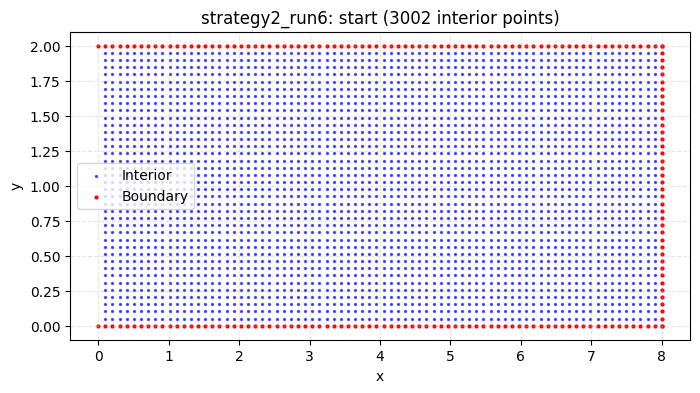

Initial energy: 344.696900670011
Initial lambda_max: 1.0012e+04, lr: 1.0000e-04
Epoch [0/15000], Energy: 344.696901, lr: 1.000e-04
Epoch [1000/15000], Energy: 0.600285, lr: 8.810e-05
Epoch [2000/15000], Energy: 0.149871, lr: 9.418e-05
Epoch [3000/15000], Energy: -0.048729, lr: 9.726e-05
Epoch [4000/15000], Energy: -0.197579, lr: 9.711e-05
Epoch [5000/15000], Energy: -0.296685, lr: 9.416e-05
Epoch [6000/15000], Energy: -0.339216, lr: 9.101e-05
Epoch [7000/15000], Energy: -0.360640, lr: 8.923e-05
Epoch [8000/15000], Energy: -0.377016, lr: 8.840e-05
Epoch [9000/15000], Energy: -0.391262, lr: 8.751e-05
Epoch [10000/15000], Energy: -0.401005, lr: 8.647e-05
Epoch [11000/15000], Energy: -0.405962, lr: 8.593e-05
Epoch [12000/15000], Energy: -0.409845, lr: 8.532e-05
Epoch [13000/15000], Energy: -0.413808, lr: 8.419e-05
Epoch [14000/15000], Energy: -0.418080, lr: 8.362e-05
energy: -0.42164829248498104
Starting L-BFGS optimization...
Final energy: -0.4216486505247926


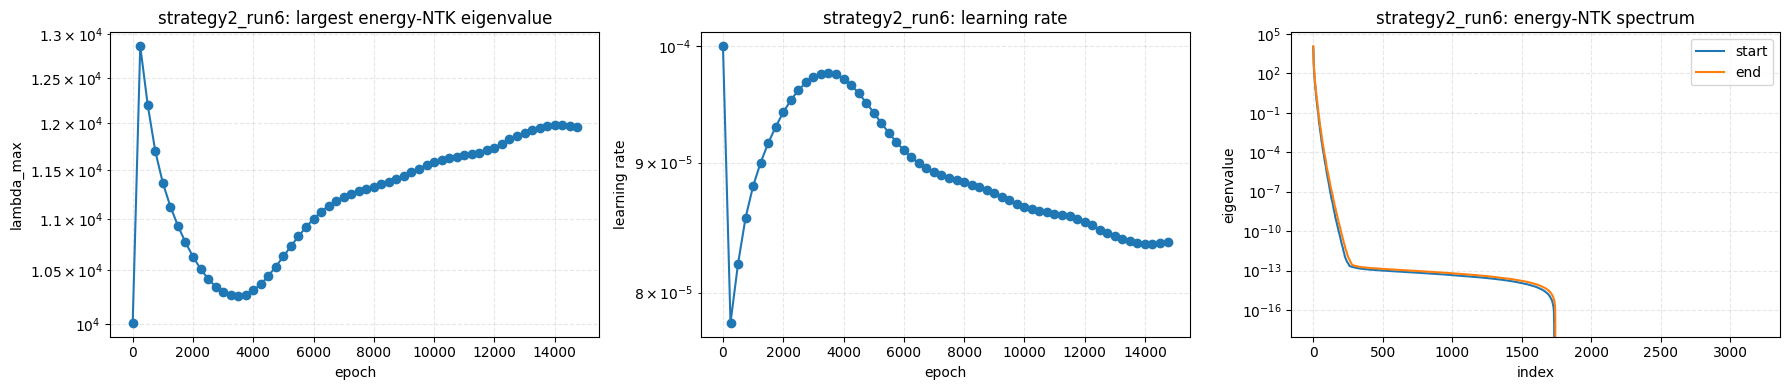

strategy2_run6  |  L2 error u: 1.171294e-01  |  L2 error v: 9.498271e-02


(<__main__.CollocPts at 0x7f6c04adf520>,
 {'start_frac': 1.0,
  'mode': 'ntk_lr',
  'base_lr': 0.0001,
  'ntk_every': 250,
  'n_ntk': 800,
  'lr_clip': 10.0,
  'lambda_max_0': 10012.230612546002,
  'lambda_max_final': 11941.21883802156,
  'final_lr': np.float64(8.373514518967014e-05),
  'n_colloc': 3002,
  'l-bfgs': True})

In [6]:
# Train the model

def original_PINN_training(name, start_frac=1.0, adam_epochs=15000, lbfgs_epochs=500, use_lbfgs=False):
    colloc_pts = original_collocation_point_scheme(start_frac)

    # Folder for this run's plots, and a record of the points
    plot_dir = os.path.join('runs', f"{name}_plots")
    os.makedirs(plot_dir, exist_ok=True)
    colloc_history = {}

    # print starting collocation points
    print("Starting collocation points:")
    colloc_history["start"] = colloc_pts.X_star.copy()
    colloc_pts.plot_collocation_points(title=f"{name}: start",
                                       save_path=os.path.join(plot_dir, "1_start.png"))


    X_star, X_boundary, x_collocation, y_collocation, \
    x_boundary_tensor, y_boundary_tensor = colloc_pts.collocation_points()

    # Initialize optimizer
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    # Training loop
    def closure():
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        return energy

    print("Initial energy:", potential_energy(colloc_pts).item())

    # First train with Adam
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    for epoch in range(adam_epochs):
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        optimizer.step()

        if epoch % 1000 == 0:
            print(f'Epoch [{epoch}/{adam_epochs}], Energy: {energy.item():.6f}')

    print("energy:", potential_energy(colloc_pts).item())

    # Then refine with L-BFGS
    if use_lbfgs:
        optimizer = optim.LBFGS(model.parameters(),
                                lr=1e-3,
                                max_iter=lbfgs_epochs,
                                max_eval=500,
                                tolerance_grad=1e-7,
                                tolerance_change=1e-7,
                                history_size=50)

        print('Starting L-BFGS optimization...')
        optimizer.step(closure)

    print("Final energy:", potential_energy(colloc_pts).item())

    metadata = {"start_frac": start_frac, "mode": "original",
                "n_colloc": len(colloc_pts.X_star), "l-bfgs": use_lbfgs}

    save_run(f"{name}", metadata, colloc_history=colloc_history)
    return colloc_pts, metadata

########### Strategy 1: Place collocation points more intentionally ################

def strategy1_PINN_training(name, start_frac, 
                            add_frac1, add_frac2,
                            frac1, frac2,
                            k1=1.0, c1=1.0, k2=1.0, c2=1.0,
                            mode1="sample", mode2="grid",
                            adam_epochs=15000, lbfgs_epochs=500,
                            use_lbfgs=False):
    # k: how "focused" the sampling is, c: how much uniform coverage kept (0/small, energy driven, large: mostly uniform)
    
    colloc_pts = original_collocation_point_scheme(start_frac)

    # Folder for this run's plots, and a record of the points at each stage
    plot_dir = os.path.join('runs', f"{name}_plots")
    os.makedirs(plot_dir, exist_ok=True)
    colloc_history = {}
    
    # print starting collocation points
    print("Starting collocation points:")
    colloc_history["start"] = colloc_pts.X_star.copy()
    colloc_pts.plot_collocation_points()

    X_star, X_boundary, x_collocation, y_collocation, \
    x_boundary_tensor, y_boundary_tensor = colloc_pts.collocation_points()

    first_stage_epochs = int(adam_epochs * frac1)
    second_stage_epochs = int(adam_epochs * frac2)

    print("Initial energy:", potential_energy(colloc_pts).item())

    # First bout with Adam
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    # Training loop
    def closure():
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        return energy

    for epoch in range(first_stage_epochs):
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        optimizer.step()

        if epoch % 1000 == 0:
            print(f'Epoch [{epoch}/{adam_epochs}], Energy: {energy.item():.6f}')

    # increase collocation point density based on potential energy struggles
    colloc_pts.add_pts(add_frac=add_frac1, mode=mode1, k=k1, c=c1)
    print("intermediate collocation points:")
    colloc_history["intermediate"] = colloc_pts.X_star.copy()
    colloc_pts.plot_collocation_points(title=f"{name}: after {mode1}",
                                       save_path=os.path.join(plot_dir, "2_intermediate.png"))

    # keep training with Adam with extra colloc points
    for epoch in range(first_stage_epochs+1, second_stage_epochs):
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        optimizer.step()
        if epoch % 1000 == 0:
            print(f'Epoch [{epoch}/{adam_epochs}], Energy: {energy.item():.6f}')

    # increase collocation point density based on potential energy struggles
    colloc_pts.add_pts(add_frac=add_frac2, mode=mode2, k=k2, c=k2)
    print("final collocation points:")
    colloc_history["final"] = colloc_pts.X_star.copy()
    colloc_pts.plot_collocation_points(title=f"{name}: after {mode2}",
                                       save_path=os.path.join(plot_dir, "3_final.png"))

    # keep training with Adam with extra colloc points
    for epoch in range(second_stage_epochs+1, adam_epochs):
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        optimizer.step()
        if epoch % 1000 == 0:
            print(f'Epoch [{epoch}/{adam_epochs}], Energy: {energy.item():.6f}')

    # Then refine with L-BFGS
    if use_lbfgs:
        optimizer = optim.LBFGS(model.parameters(),
                                lr=1e-3,
                                max_iter=lbfgs_epochs,
                                max_eval=500,
                                tolerance_grad=1e-7,
                                tolerance_change=1e-7,
                                history_size=50)

        print('Starting L-BFGS optimization...')
        optimizer.step(closure)


    print("Final energy:", potential_energy(colloc_pts).item())

    metadata = {"start_frac": start_frac,
                    "mode1": mode1, "mode2": mode2,
                    "add_frac1": add_frac1, "add_frac2": add_frac2,
                    "frac1": frac1, "frac2": frac2,
                    "k1": k1, "c1": c1, "k2": k2, "c2": c2,
                    "n_colloc": len(colloc_pts.X_star), "l-bfgs": use_lbfgs}
    
    save_run(f"{name}", metadata, colloc_history=colloc_history)
    return colloc_pts, metadata

######## Strategy 2 : Adam w/ NTK-adjusted learning rate ####################

from torch.func import functional_call, jacrev, vmap, grad

def compute_ntk(colloc_pts, n_ntk=300):
    """
    Energy NTK  K = J_e J_e^T  on a fixed random subset of collocation points.

    The strain energy is written as U = 1/2 ||e||^2 with, at each point i,
        e_i = sqrt(w_i) * [ sqrt(lambda) (eps_xx + eps_yy),
                            sqrt(2 mu)   eps_xx,
                            sqrt(2 mu)   eps_yy,
                            2 sqrt(mu)   eps_xy ]
    Rows of K are ordered by error type: [vol | xx | yy | xy], n_ntk rows each.

    Returns a dict with
        K      : (4n, 4n) kernel matrix
        blocks : slices for each error type, e.g. K[blocks["xy"], blocks["xy"]]
        idx    : indices of the subset in colloc_pts.X_star
        X_ntk  : coordinates of the subset
    """
    # Fixed subset (same seed -> same points every call, so changes reflect training)
    rng = np.random.default_rng(42)
    N = len(colloc_pts.X_star)
    n = min(n_ntk, N)
    idx = rng.choice(N, n, replace=False)
    X_ntk = colloc_pts.X_star[idx]
    w_ntk = colloc_pts.weights[idx].reshape(-1).detach() * (N / n)   # rescale subset to full domain

    params = {name: p.detach() for name, p in model.named_parameters()}

    # Strains at one point as a function of the network parameters
    # (g_u, g_v don't depend on the parameters, so they drop out)
    def point_strain(p, x, y):
        def u_fn(x, y):
            u_NN, _ = functional_call(model, p, (x.reshape(1, 1), y.reshape(1, 1)))
            return (polynomial_distance(x, L) * u_NN).squeeze()

        def v_fn(x, y):
            _, v_NN = functional_call(model, p, (x.reshape(1, 1), y.reshape(1, 1)))
            return (polynomial_distance(x, L) * v_NN).squeeze()

        u_x, u_y = grad(u_fn, argnums=(0, 1))(x, y)
        v_x, v_y = grad(v_fn, argnums=(0, 1))(x, y)
        return torch.stack([u_x, v_y, 0.5 * (u_y + v_x)])   # eps_xx, eps_yy, eps_xy

    x_ntk = torch.tensor(X_ntk[:, 0], device=device)
    y_ntk = torch.tensor(X_ntk[:, 1], device=device)

    # Parameter Jacobian of the strains at every point: (n, 3, n_params)
    J_eps = vmap(jacrev(point_strain), in_dims=(None, 0, 0))(params, x_ntk, y_ntk)
    J_eps = torch.cat([j.reshape(n, 3, -1) for j in J_eps.values()], dim=2)

    # Parameter Jacobian of the errors e, ordered [vol | xx | yy | xy]: (4n, n_params)
    sqrt_w = torch.sqrt(w_ntk)[:, None]
    J_vol = sqrt_w * np.sqrt(lambda_) * (J_eps[:, 0, :] + J_eps[:, 1, :])
    J_xx  = sqrt_w * np.sqrt(2 * mu) * J_eps[:, 0, :]
    J_yy  = sqrt_w * np.sqrt(2 * mu) * J_eps[:, 1, :]
    J_xy  = sqrt_w * 2 * np.sqrt(mu) * J_eps[:, 2, :]
    J_e = torch.cat([J_vol, J_xx, J_yy, J_xy], dim=0)

    K = (J_e @ J_e.T).detach()

    blocks = {"vol": slice(0, n), "xx": slice(n, 2*n),
              "yy": slice(2*n, 3*n), "xy": slice(3*n, 4*n)}

    return {"K": K, "blocks": blocks, "idx": idx, "X_ntk": X_ntk}


def ntk_summary(ntk):
    """Eigenvalues and traces of an NTK from compute_ntk."""
    K = ntk["K"]
    eigenvalues = torch.linalg.eigvalsh(K).cpu().numpy()   # ascending
    summary = {"lambda_max": float(eigenvalues[-1]),
               "lambda_min": float(eigenvalues[0]),
               "trace": float(torch.trace(K))}
    for name, s in ntk["blocks"].items():
        summary[f"trace_{name}"] = float(torch.trace(K[s, s]))
    summary["eigenvalues"] = eigenvalues
    return summary

    
def strategy2_PINN_training(name, start_frac=1.0, adam_epochs=15000, lbfgs_epochs=500,
                            use_lbfgs=False, base_lr=1e-4,
                            ntk_every=500, n_ntk=300, lr_clip=10.0):
    """
    Adam with an NTK-adjusted learning rate:
        lr = base_lr * lambda_max_0 / lambda_max, clipped to
             [base_lr / lr_clip, base_lr * lr_clip]
    base_lr   : learning rate at the start of training
    ntk_every : epochs between NTK updates
    n_ntk     : collocation points used to estimate the NTK
    lr_clip   : how far the learning rate can move from base_lr (factor)
    """

    colloc_pts = original_collocation_point_scheme(start_frac)

    # Folder for this run's plots, and a record of the points
    plot_dir = os.path.join('runs', f"{name}_plots")
    os.makedirs(plot_dir, exist_ok=True)
    colloc_history = {}

    # print starting collocation points
    print("Starting collocation points:")
    colloc_history["start"] = colloc_pts.X_star.copy()
    colloc_pts.plot_collocation_points(title=f"{name}: start",
                                       save_path=os.path.join(plot_dir, "1_start.png"))

    print("Initial energy:", potential_energy(colloc_pts).item())

    # Initial NTK and learning rate
    ntk = compute_ntk(colloc_pts, n_ntk)
    summary = ntk_summary(ntk)
    lambda_max_0 = summary["lambda_max"]
    lr = base_lr
    ntk_history = [{"epoch": 0, "lr": lr, **summary}]
    print(f"Initial lambda_max: {lambda_max_0:.4e}, lr: {lr:.4e}")

    # Training loop
    def closure():
        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        return energy

    # First train with Adam
    optimizer = optim.Adam(model.parameters(), lr=lr)

    for epoch in range(adam_epochs):
        # Update learning rate from the NTK
        if epoch > 0 and epoch % ntk_every == 0:
            ntk = compute_ntk(colloc_pts, n_ntk)
            summary = ntk_summary(ntk)
            lr = base_lr * np.clip(lambda_max_0 / summary["lambda_max"], 1 / lr_clip, lr_clip)
            for group in optimizer.param_groups:
                group["lr"] = lr
            ntk_history.append({"epoch": epoch, "lr": lr, **summary})

        optimizer.zero_grad()
        energy = potential_energy(colloc_pts)
        energy.backward()
        optimizer.step()

        if epoch % 1000 == 0:
            print(f'Epoch [{epoch}/{adam_epochs}], Energy: {energy.item():.6f}, lr: {lr:.3e}')

    print("energy:", potential_energy(colloc_pts).item())

    # Then refine with L-BFGS
    if use_lbfgs:
        optimizer = optim.LBFGS(model.parameters(),
                                lr=1e-3,
                                max_iter=lbfgs_epochs,
                                max_eval=500,
                                tolerance_grad=1e-7,
                                tolerance_change=1e-7,
                                history_size=50)

        print('Starting L-BFGS optimization...')
        optimizer.step(closure)

    print("Final energy:", potential_energy(colloc_pts).item())

    # NTK after training (including L-BFGS, if used)
    final_summary = ntk_summary(compute_ntk(colloc_pts, n_ntk))

    # Plot and save the NTK / learning-rate history
    epochs_hist = [h["epoch"] for h in ntk_history]
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))

    ax[0].semilogy(epochs_hist, [h["lambda_max"] for h in ntk_history], "o-")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("lambda_max")
    ax[0].set_title(f"{name}: largest energy-NTK eigenvalue")

    ax[1].semilogy(epochs_hist, [h["lr"] for h in ntk_history], "o-")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("learning rate")
    ax[1].set_title(f"{name}: learning rate")

    ax[2].semilogy(ntk_history[0]["eigenvalues"][::-1], label="start")
    ax[2].semilogy(final_summary["eigenvalues"][::-1], label="end")
    ax[2].set_xlabel("index"); ax[2].set_ylabel("eigenvalue")
    ax[2].set_title(f"{name}: energy-NTK spectrum")
    ax[2].legend()

    for a in ax:
        a.grid(True, which="both", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plot_dir, "ntk_history.png"), dpi=150, bbox_inches="tight")
    plt.show()

    metadata = {"start_frac": start_frac, "mode": "ntk_lr",
                "base_lr": base_lr, "ntk_every": ntk_every, "n_ntk": n_ntk,
                "lr_clip": lr_clip, "lambda_max_0": lambda_max_0,
                "lambda_max_final": final_summary["lambda_max"], "final_lr": lr,
                "n_colloc": len(colloc_pts.X_star), "l-bfgs": use_lbfgs}

    save_run(f"{name}", metadata, colloc_history=colloc_history)
    return colloc_pts, metadata


############## Train with different strategies ################

#original_PINN_training(name="original_strategy_plane_stress", use_lbfgs=True)
'''strategy1_PINN_training(name="strategy1_run4",
                        start_frac=0.1, 
                        add_frac1=0.3, add_frac2=0.6, 
                        frac1=0.15, frac2=0.4, 
                        k1=2.0, c1=1.0, k2=2.0, c2=1.0,
                        mode1="sample", mode2="grid",
                        use_lbfgs=True)'''
strategy2_PINN_training(name='strategy2_run6',use_lbfgs=True, ntk_every=250, n_ntk=800)
#strategy3_PINN_training(name="cosine_1e-3", use_lbfgs=True)

In [7]:
def expressivity_test(name="expressivity_test", epochs=20000, lr=1e-3):
    """Fit net_u/net_v directly to the exact solution on the test grid, then save."""
    # Common testing grid (same as save_run)
    x_test = np.linspace(0, L, 2*Nx)
    y_test = np.linspace(0, W, 2*Ny)
    X_test, Y_test = np.meshgrid(x_test, y_test)
    X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

    x_t = torch.tensor(X_star_test[:, 0:1], device=device)
    y_t = torch.tensor(X_star_test[:, 1:2], device=device)

    def u_exact(x, y):
        term1 = (P * (y-W/2)) / (6 * E * I)
        term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4)
        return -term1 * term2

    def v_exact(x, y):
        term1 = -(P) / (6 * E * I)
        term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
        return -term1 * term2

    u_target = u_exact(x_t, y_t)
    v_target = v_exact(x_t, y_t)

    # Fit directly to the exact solution
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_history = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = ((net_u(x_t, y_t) - u_target)**2).mean() / (u_target**2).mean() \
             + ((net_v(x_t, y_t) - v_target)**2).mean() / (v_target**2).mean()
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
        if epoch % 2000 == 0:
            print(f"Epoch [{epoch}/{epochs}], fit loss: {loss.item():.3e}")

    metadata = {"mode": "expressivity_fit", "fit_epochs": epochs, "fit_lr": lr,
                "final_fit_loss": loss_history[-1]}

    save_run(name, metadata)
    return metadata

#expressivity_test()

In [8]:
# Testing the model
x_test = np.linspace(0, L, 2*Nx)
y_test = np.linspace(0, W, 2*Ny)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Convert to torch tensors
x_test_tensor = torch.tensor(X_star_test[:, 0:1], requires_grad=True, device=device)
y_test_tensor = torch.tensor(X_star_test[:, 1:2], requires_grad=True, device=device)

# Predict displacements
u_pred = net_u(x_test_tensor, y_test_tensor).cpu().detach().numpy()
v_pred = net_v(x_test_tensor, y_test_tensor).cpu().detach().numpy()


def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4)
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

u_exact_val = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
v_exact_val = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2])
# Compute errors
error_u = np.linalg.norm(u_exact_val - u_pred, 2) / np.linalg.norm(u_exact_val, 2)
error_v = np.linalg.norm(v_exact_val - v_pred, 2) / np.linalg.norm(v_exact_val, 2)
print(f'Relative L2 error in u: {error_u:e}')
print(f'Relative L2 error in v: {error_v:e}')

Relative L2 error in u: 1.171294e-01
Relative L2 error in v: 9.498271e-02


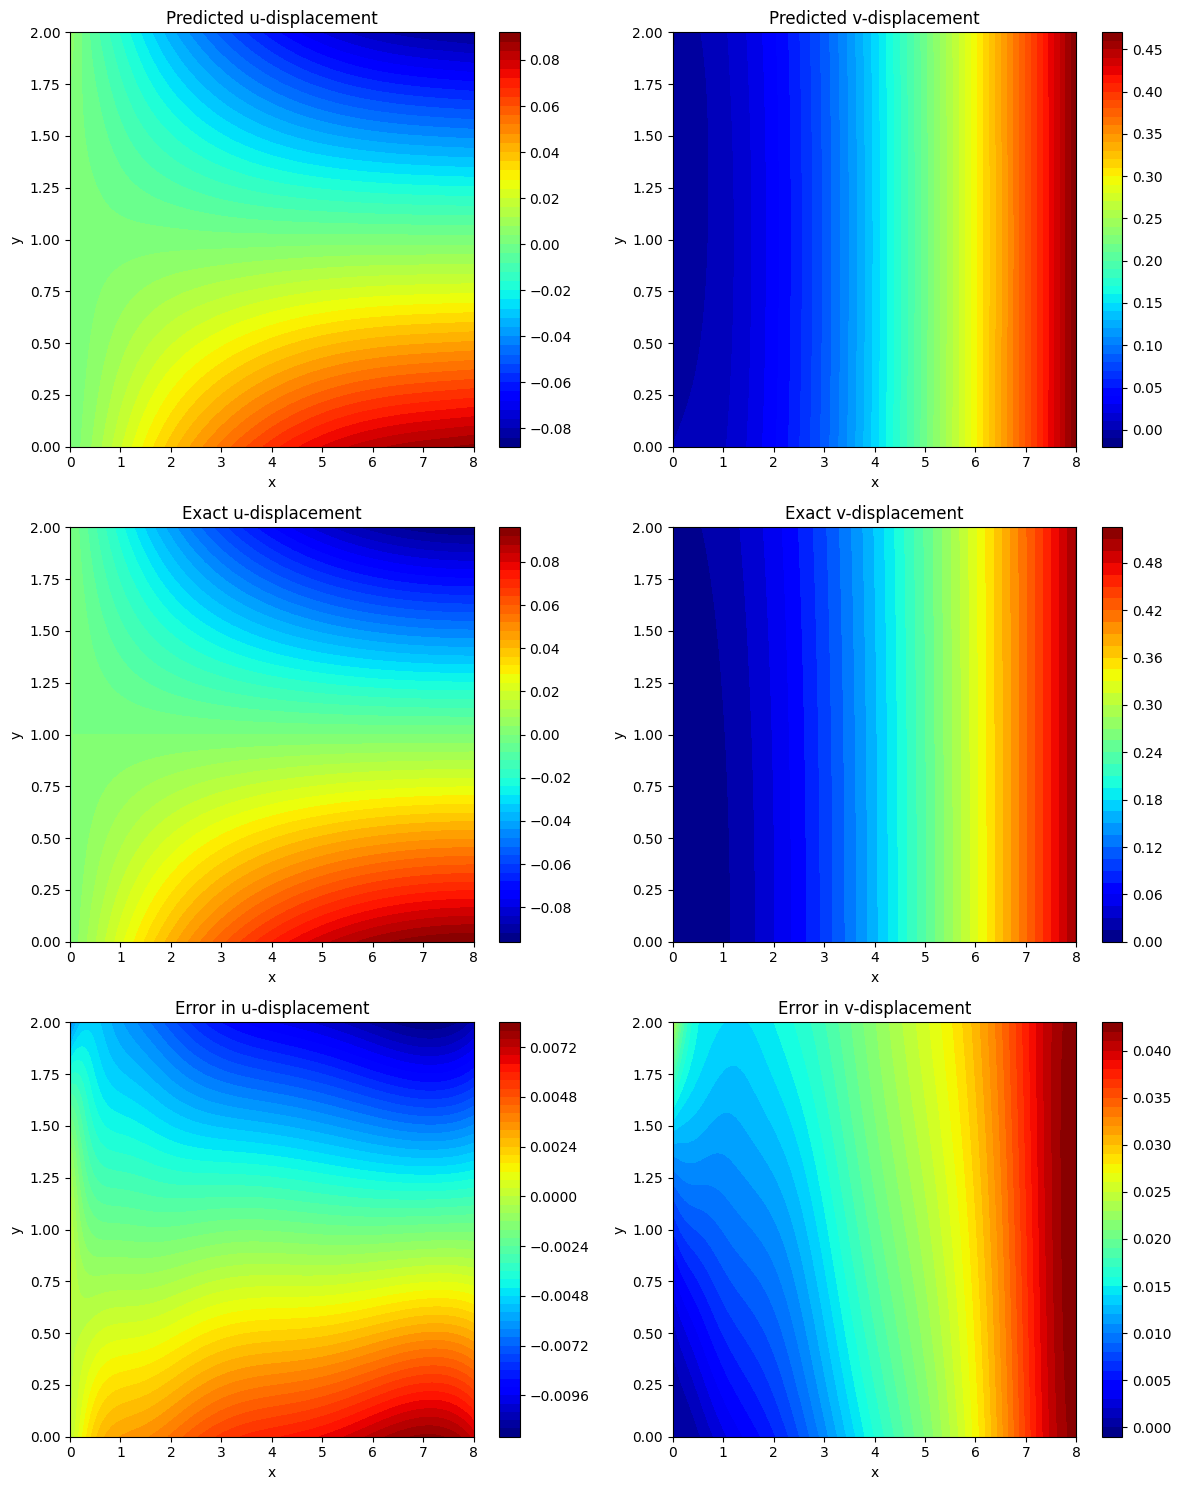

In [9]:
# Reshape data for plotting
U_pred = u_pred.reshape(2*Ny, 2*Nx)
V_pred = v_pred.reshape(2*Ny, 2*Nx)
U_exact = u_exact_val.reshape(2*Ny, 2*Nx)
V_exact = v_exact_val.reshape(2*Ny, 2*Nx)
Error_U = (U_exact - U_pred)
Error_V = (V_exact - V_pred)

# Plotting the results2
fig, ax = plt.subplots(3, 2, figsize=(12, 15))

# Predicted displacements
cf = ax[0, 0].contourf(X_test, Y_test, U_pred, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 0])
ax[0, 0].set_title('Predicted u-displacement')
ax[0, 0].set_xlabel('x')
ax[0, 0].set_ylabel('y')

cf = ax[0, 1].contourf(X_test, Y_test, V_pred, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[0, 1])
ax[0, 1].set_title('Predicted v-displacement')
ax[0, 1].set_xlabel('x')
ax[0, 1].set_ylabel('y')

# Exact displacements
cf = ax[1, 0].contourf(X_test, Y_test, U_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 0])
ax[1, 0].set_title('Exact u-displacement')
ax[1, 0].set_xlabel('x')
ax[1, 0].set_ylabel('y')

cf = ax[1, 1].contourf(X_test, Y_test, V_exact, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[1, 1])
ax[1, 1].set_title('Exact v-displacement')
ax[1, 1].set_xlabel('x')
ax[1, 1].set_ylabel('y')

# Errors
cf = ax[2, 0].contourf(X_test, Y_test, Error_U, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 0])
ax[2, 0].set_title('Error in u-displacement')
ax[2, 0].set_xlabel('x')
ax[2, 0].set_ylabel('y')

cf = ax[2, 1].contourf(X_test, Y_test, Error_V, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax[2, 1])
ax[2, 1].set_title('Error in v-displacement')
ax[2, 1].set_xlabel('x')
ax[2, 1].set_ylabel('y')

plt.tight_layout()
plt.show()

In [10]:
#colloc_pts = original_collocation_point_scheme(start_frac=1.0)
#print("Energy of best-fit network:", potential_energy(colloc_pts).item())